# 04 · Capacity Assessment
*EV capacity planning for PowerCharge Utilities · notebook 4 of 8 · Anna Tafri*

Reads: `data/processed/ev_events_clean.csv`, `substations_clean.csv`  
Writes: `data/processed/substation_capacity.csv`, `reports/capacity_scenarios.csv`, `reports/figures/04_*.png`

### Business question
> How much EV growth can each substation absorb before it breaches its planning limit, and which ones break first?

### The core problem: energy is not power
The EV data records energy (kWh per event). Substation capacity is a power limit (MW). A substation does not fail because a lot of energy flows through it over a month. It fails when too much power is drawn at the same moment. So we need a defensible way to turn charging records into a peak power demand, and we need to be honest about the assumptions that requires.


## 1. Method and assumptions
All assumptions are collected in one dictionary so they are visible, auditable, and easy to change.

| Assumption | Base value | Why | Tested range |
|---|---|---|---|
| Charger rating (kW) | Type 1 = 7.4, Type 2 = 22, DC Fast = 50 | Typical nameplate ratings (Notebook 02) | Low (3.7 / 11 / 50) to High (7.4 / 22 / 150 kW DC) |
| Coincidence factor | 0.7 | Not every connected charger draws full power at the same moment. EDA showed the evening peak gathers sessions but does not synchronise all of them. | 0.5 – 1.0 |
| Existing base-load utilisation | 65% of capacity | No non-EV load data was provided. 60–70% is a common peak loading for distribution substations. | 55% – 75% |
| Planning limit | 80% of capacity | Common utility trigger for reinforcement planning. Keeps a margin for contingencies (N-1). | 75% – 90% |
| Growth scenarios | 5×, 10×, 20×, 40× today's EV load | 38 days of data cannot support a forecast (Notebook 03), so scenarios bracket plausible adoption paths | - |

**Model, per substation:**
- EV peak (MW) = Σ (number of EVs × charger kW) × coincidence factor ÷ 1000
- Peak utilisation = base-load share + (EV peak × growth) ÷ capacity
- Breaking multiple = how many times today's EV load the substation can absorb before reaching the planning limit = (planning limit − base load) × capacity ÷ EV peak

The breaking multiple is the key metric. It answers the executive question *"how long until this substation needs attention?"* in one number that does not depend on choosing a scenario.

## 2. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ev_utils import capacity_model

pd.set_option("display.float_format", "{:,.2f}".format)

# Project chart style (same as Notebook 03)
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
STATUS = {"Within limit": "#0ca30c", "Above planning limit": "#fab219", "Overloaded": "#d03b3b"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

events = pd.read_csv(PROCESSED / "ev_events_clean.csv", parse_dates=["timestamp"])
subs = pd.read_csv(PROCESSED / "substations_clean.csv")
print(events.shape, subs.shape)

(97, 30) (50, 4)


In [2]:
CHARGER_KW_SETS = {
    "Low":  {"Type 1": 3.7, "Type 2": 11.0, "DC Fast": 50.0},
    "Base": {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 50.0},
    "High": {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 150.0},
}
BASE = {
    "charger_kw": CHARGER_KW_SETS["Base"],
    "coincidence": 0.7,
    "base_load_util": 0.65,
    "planning_limit": 0.80,
}
SCENARIOS = {"Today": 1, "Low (5x)": 5, "Medium (10x)": 10, "High (20x)": 20, "Stress (40x)": 40}

def status(util, limit=BASE["planning_limit"]):
    return np.select([util >= 1.0, util >= limit], ["Overloaded", "Above planning limit"], "Within limit")

## 3. Today's EV peak demand

In [3]:
today = capacity_model(events, subs, **BASE)
today["ev_share_of_capacity"] = today["ev_peak_mw"] / today["capacity_mw"]

summary = pd.Series({
    "Total EV peak demand (MW)": today["ev_peak_mw"].sum(),
    "Total substation capacity (MW)": today["capacity_mw"].sum(),
    "EV peak as % of capacity (network)": today["ev_peak_mw"].sum() / today["capacity_mw"].sum(),
    "Largest EV share at one substation": today["ev_share_of_capacity"].max(),
    "Highest peak utilisation today": today["utilisation"].max(),
})
pct = ["EV peak as % of capacity (network)", "Largest EV share at one substation", "Highest peak utilisation today"]
summary.to_frame("value").style.format("{:,.1f}").format("{:.1%}", subset=pd.IndexSlice[pct, :])

,value
Total EV peak demand (MW),10.4
Total substation capacity (MW),"2,637.0"
EV peak as % of capacity (network),0.4%
Largest EV share at one substation,1.6%
Highest peak utilisation today,66.6%


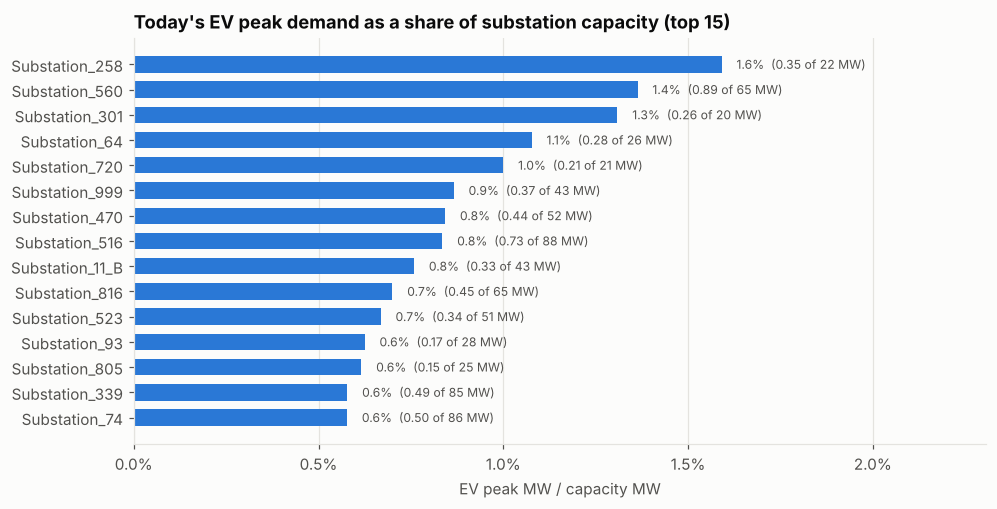

In [4]:
top = today.sort_values("ev_share_of_capacity", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(top.index, top["ev_share_of_capacity"], color=BLUE, height=0.65)
for yi, (v, mw, cap) in enumerate(zip(top["ev_share_of_capacity"], top["ev_peak_mw"], top["capacity_mw"])):
    ax.text(v + 0.0004, yi, f"{v:.1%}  ({mw:.2f} of {cap:.0f} MW)", va="center", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set(title="Today's EV peak demand as a share of substation capacity (top 15)",
       xlabel="EV peak MW / capacity MW", xlim=(0, top["ev_share_of_capacity"].max() * 1.45))
ax.grid(axis="y", visible=False)
save(fig, "04_01_ev_share_today"); plt.show()

**Reading it**
- Today, EV charging adds only ~0.1% to 1.6% of a substation's capacity at peak. No substation is at risk now. The highest peak utilisation is about 67%, which is still below the 80% planning limit.
- The ranking is still informative. Small substations with several sites attached (Substation_258: 22 MW, Substation_301: 20 MW) already carry the largest EV share. These are the ones that will feel growth first.

Why it matters: the question for PowerCharge is not *"are we overloaded today?"* but *"how much growth can we absorb, and where does it run out first?"*

## 4. Breaking multiple: how much growth can each substation absorb?

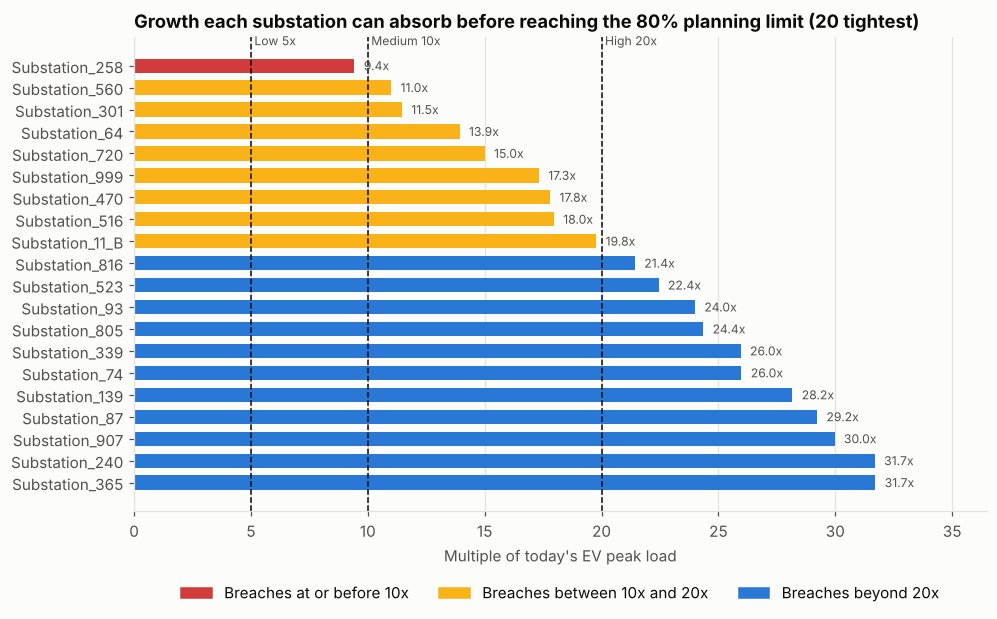

Median breaking multiple: 37x | tightest: Substation_258 at 9.4x
Breach by 10x: 1 | by 20x: 9 | by 40x: 26 of 50


In [5]:
brk = today["breaking_multiple"].dropna().sort_values()
show = brk.head(20).iloc[::-1]

def band_color(m):
    return "#d03b3b" if m <= 10 else ("#fab219" if m <= 20 else BLUE)

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(show.index, show.values, color=[band_color(m) for m in show.values], height=0.65)
for x, label in [(5, "Low 5x"), (10, "Medium 10x"), (20, "High 20x")]:
    ax.axvline(x, color=INK, linewidth=1, linestyle="--")
    ax.text(x, len(show) - 0.2, f" {label}", fontsize=8, color=INK_2, va="bottom")
for yi, v in enumerate(show.values):
    ax.text(v + 0.4, yi, f"{v:.1f}x", va="center", fontsize=8, color=INK_2)
ax.set(title="Growth each substation can absorb before reaching the 80% planning limit (20 tightest)",
       xlabel="Multiple of today's EV peak load", xlim=(0, show.max() * 1.15))
ax.legend(handles=[Patch(color="#d03b3b", label="Breaches at or before 10x"),
                   Patch(color="#fab219", label="Breaches between 10x and 20x"),
                   Patch(color=BLUE, label="Breaches beyond 20x")],
          loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3)
ax.grid(axis="y", visible=False)
save(fig, "04_02_breaking_multiple"); plt.show()

print(f"Median breaking multiple: {brk.median():.0f}x | tightest: {brk.index[0]} at {brk.iloc[0]:.1f}x")
print(f"Breach by 10x: {(brk <= 10).sum()} | by 20x: {(brk <= 20).sum()} | by 40x: {(brk <= 40).sum()} of {len(today)}")

**Reading it**
- The tightest substation, Substation_258, reaches its planning limit at ~9× today's EV load. Substation_560 and Substation_301 follow at about 11×.
- 9 substations breach by 20×. The median substation can take ~37× before it needs attention.
- For context, EV fleets in fast-adopting markets have grown roughly 5–10× within 5–7 years. A 10–20× scenario is therefore a realistic medium-term planning horizon, not an extreme case.

## 5. Scenario analysis

In [6]:
rows = []
for name, g in SCENARIOS.items():
    r = capacity_model(events, subs, growth=g, **BASE)
    r["scenario"], r["growth"], r["status"] = name, g, status(r["utilisation"])
    rows.append(r.reset_index())
scen = pd.concat(rows, ignore_index=True)

scen_summary = (scen.groupby(["scenario", "growth"], sort=False)
                    .agg(max_utilisation=("utilisation", "max"),
                         within_limit=("status", lambda s: (s == "Within limit").sum()),
                         above_limit=("status", lambda s: (s == "Above planning limit").sum()),
                         overloaded=("status", lambda s: (s == "Overloaded").sum()),
                         network_headroom_mw=("headroom_mw", lambda h: h.clip(lower=0).sum()))
                    .reset_index())
scen_summary.to_csv(REPORTS / "capacity_scenarios.csv", index=False)
scen_summary

,scenario,growth,max_utilisation,within_limit,above_limit,overloaded,network_headroom_mw
0,Today,1,0.67,50,0,0,385.19
1,Low (5x),5,0.73,50,0,0,343.74
2,Medium (10x),10,0.81,49,1,0,292.12
3,High (20x),20,0.97,41,9,0,208.49
4,Stress (40x),40,1.29,24,21,5,126.95


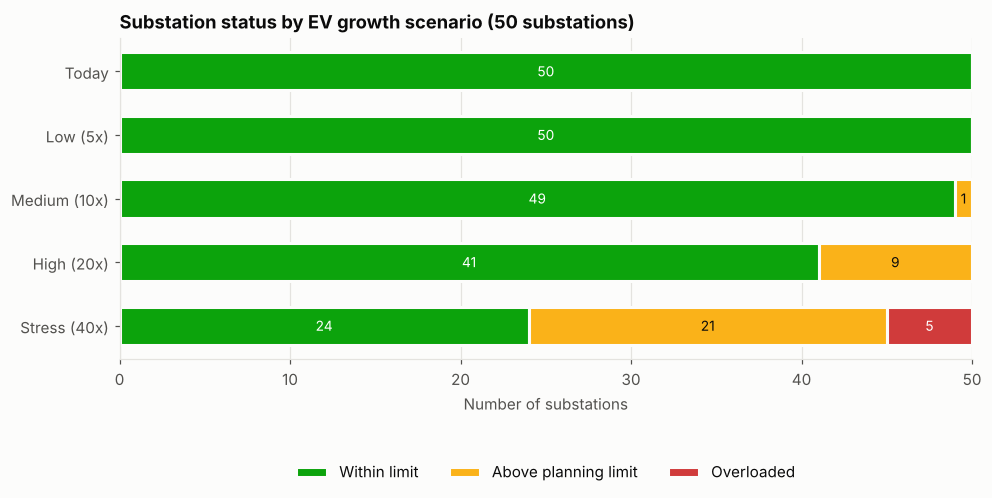

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
names = scen_summary["scenario"]
left = np.zeros(len(names))
for label, col in [("Within limit", "within_limit"), ("Above planning limit", "above_limit"), ("Overloaded", "overloaded")]:
    vals = scen_summary[col].values
    ax.barh(names, vals, left=left, color=STATUS[label], height=0.6, edgecolor=SURFACE, linewidth=2, label=label)
    for yi, (l, v) in enumerate(zip(left, vals)):
        if v > 0:
            ax.text(l + v / 2, yi, str(v), ha="center", va="center", fontsize=9,
                    color="white" if label != "Above planning limit" else INK)
    left += vals
ax.invert_yaxis()
ax.set(title="Substation status by EV growth scenario (50 substations)", xlabel="Number of substations", xlim=(0, 50))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=3)
ax.grid(axis="y", visible=False)
save(fig, "04_03_scenario_status"); plt.show()

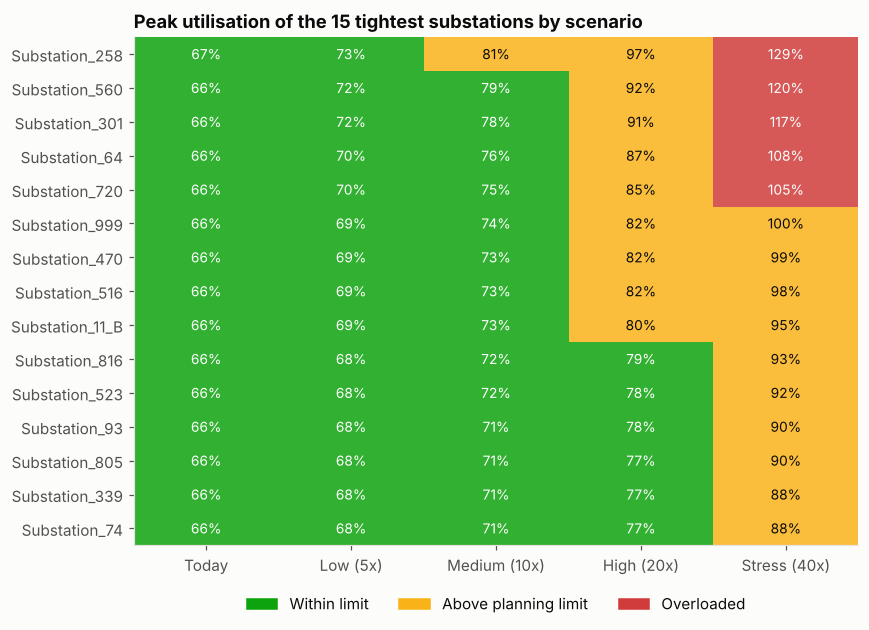

In [8]:
# Utilisation heatmap: the 15 tightest substations across scenarios
tight = brk.head(15).index
heat = scen.pivot_table(index="substation_id", columns="scenario", values="utilisation", sort=False).loc[tight, list(SCENARIOS)]

from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap([STATUS["Within limit"], STATUS["Above planning limit"], STATUS["Overloaded"]])
norm = BoundaryNorm([0, 0.8, 1.0, 10], cmap.N)

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.imshow(heat.values, cmap=cmap, norm=norm, aspect="auto", alpha=0.85)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v >= 1 or v < 0.8 else INK)
ax.grid(False)
ax.set_title("Peak utilisation of the 15 tightest substations by scenario")
ax.legend(handles=[Patch(color=c, label=l) for l, c in STATUS.items()],
          loc="lower center", bbox_to_anchor=(0.5, -0.16), ncol=3)
save(fig, "04_04_utilisation_heatmap"); plt.show()

**Reading it**
- **Today and at 5×:** every substation stays within the planning limit.
- **At 10×:** Substation_258 crosses 80%. This is the first trigger for reinforcement planning.
- **At 20×:** 9 substations are above the planning limit, though none is overloaded yet.
- **At 40×:** 5 substations pass 100%, which would mean real overloads, voltage problems, and outages. Another 21 sit above the planning limit.

Utilisation rises linearly with growth. The slope differs by substation (EV load relative to capacity), and that slope is what separates early breakers from late ones.

## 6. Sensitivity analysis: which assumption matters most?
One set of assumptions isn't enough to plan on. Below, each assumption is moved to its low and high value one at a time, and we count how many substations exceed the planning limit in the Medium (10×) scenario.

In [9]:
def n_at_risk(growth=10, **override):
    params = {**BASE, **override}
    r = capacity_model(events, subs, growth=growth, **params)
    return int((r["utilisation"] >= params["planning_limit"]).sum())

baseline = n_at_risk()
tests = {
    "Base-load utilisation (55% / 75%)": (n_at_risk(base_load_util=0.55), n_at_risk(base_load_util=0.75)),
    "Charger rating (Low / High DC 150 kW)": (n_at_risk(charger_kw=CHARGER_KW_SETS["Low"]), n_at_risk(charger_kw=CHARGER_KW_SETS["High"])),
    "Coincidence factor (0.5 / 1.0)": (n_at_risk(coincidence=0.5), n_at_risk(coincidence=1.0)),
    "Planning limit (90% / 75%)": (n_at_risk(planning_limit=0.90), n_at_risk(planning_limit=0.75)),
}
sens = (pd.DataFrame(tests, index=["optimistic", "pessimistic"]).T
          .assign(swing=lambda t: t["pessimistic"] - t["optimistic"]).sort_values("swing"))
sens

,optimistic,pessimistic,swing
Coincidence factor (0.5 / 1.0),0,4,4
Planning limit (90% / 75%),0,5,5
Charger rating (Low / High DC 150 kW),1,14,13
Base-load utilisation (55% / 75%),0,18,18


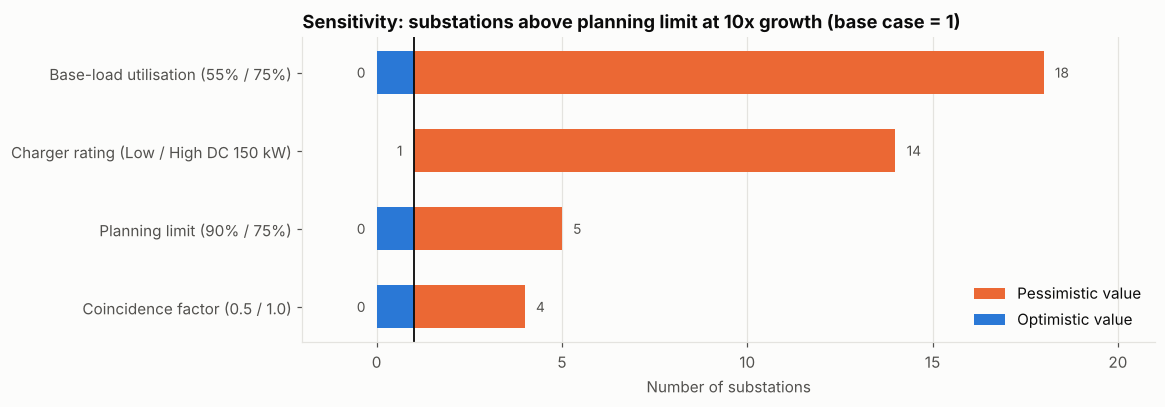

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(sens))
ax.barh(y, sens["pessimistic"] - baseline, left=baseline, color=ORANGE, height=0.55, label="Pessimistic value")
ax.barh(y, sens["optimistic"] - baseline, left=baseline, color=BLUE, height=0.55, label="Optimistic value")
ax.axvline(baseline, color=INK, linewidth=1.2)
for yi, (lo, hi) in enumerate(zip(sens["optimistic"], sens["pessimistic"])):
    ax.text(hi + 0.3, yi, str(hi), va="center", fontsize=9, color=INK_2)
    ax.text(lo - 0.3, yi, str(lo), va="center", ha="right", fontsize=9, color=INK_2)
ax.set_yticks(y, sens.index)
ax.set(title=f"Sensitivity: substations above planning limit at 10x growth (base case = {baseline})",
       xlabel="Number of substations", xlim=(-2, sens["pessimistic"].max() + 3))
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "04_05_sensitivity_tornado"); plt.show()

**Reading it**
- Existing base load is by far the most important unknown. If substations already run at 75% before EVs, 18 of 50 breach at 10× growth instead of 1. We do not have this data, and it is the most valuable dataset PowerCharge could add.
- **Charger technology is second.** If DC fast chargers move from 50 kW to 150 kW, which is where the market is heading, 14 substations breach. The shift to faster charging is a bigger risk than adding more EVs.
- The coincidence factor and the planning limit change the answer far less.

Why it matters: the recommendation is not just "upgrade X". It is also "collect substation SCADA peak-load data and track the charger mix", because those two inputs drive most of the uncertainty in the plan.

## 7. Method cross-check: energy-based estimate

As a sanity check, we estimate EV peak a second, independent way: spread each event's kWh over the 4-hour evening window (kWh ÷ 4 h). If the two methods rank substations similarly, the ranking is robust even if the absolute MW are uncertain.

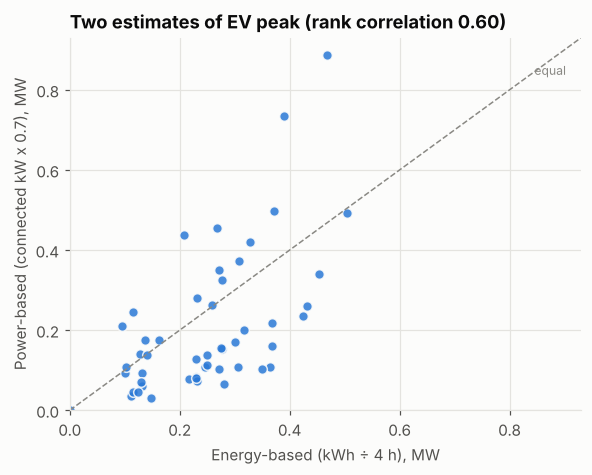

Network EV peak: power-based 10.4 MW vs energy-based 12.4 MW


In [11]:
energy_mw = (events.groupby("substation_id")["electricity_consumption_kwh"].sum() / 4 / 1000
             ).reindex(today.index, fill_value=0)
rank_corr = today["ev_peak_mw"].rank().corr(energy_mw.rank())

fig, ax = plt.subplots(figsize=(6, 4.4))
ax.scatter(energy_mw, today["ev_peak_mw"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1, alpha=0.85)
lim = max(energy_mw.max(), today["ev_peak_mw"].max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, linestyle="--", linewidth=1)
ax.text(lim * 0.97, lim * 0.9, "equal", color=MUTED, fontsize=8, ha="right")
ax.set(title=f"Two estimates of EV peak (rank correlation {rank_corr:.2f})",
       xlabel="Energy-based (kWh ÷ 4 h), MW", ylabel="Power-based (connected kW x 0.7), MW", xlim=(0, lim), ylim=(0, lim))
save(fig, "04_06_method_crosscheck"); plt.show()
print(f"Network EV peak: power-based {today['ev_peak_mw'].sum():.1f} MW vs energy-based {energy_mw.sum():.1f} MW")

**Reading it**
- The network totals are close (10.4 MW power-based vs 12.4 MW energy-based), so the absolute scale of the problem is not an artefact of one method.
- Rank agreement is moderate (0.60). The power-based method spreads substations further apart because it reflects fleet size and charger speed, which the energy method ignores.
- We keep the power-based method as primary, because capacity limits are about simultaneous power draw. Substations that rank high on *both* methods (top-right of the chart) are the most robust bottleneck candidates, and Notebook 05 will reward that agreement.

## 8. Save outputs for the bottleneck analysis

In [12]:
out = today.copy()
for name, g in SCENARIOS.items():
    if g == 1:
        continue
    out[f"util_{g}x"] = capacity_model(events, subs, growth=g, **BASE)["utilisation"]
out["status_10x"] = status(out["util_10x"])
out["status_20x"] = status(out["util_20x"])
out = out.join(subs.set_index("substation_id")[["sub_lat", "sub_lon"]])
out.sort_values("breaking_multiple").to_csv(PROCESSED / "substation_capacity.csv")
print(f"saved substation_capacity.csv {out.shape}")
out.sort_values("breaking_multiple").head(10)

saved substation_capacity.csv (50, 16)


,capacity_mw,ev_peak_mw,base_load_mw,peak_load_mw,utilisation,headroom_mw,breaking_multiple,ev_share_of_capacity,util_5x,util_10x,util_20x,util_40x,status_10x,status_20x,sub_lat,sub_lon
substation_id,,,,,,,,,,,,,,,,
Substation_258,22,0.35,14.30,14.65,0.67,2.95,9.43,0.02,0.73,0.81,0.97,1.29,Above planning limit,Above planning limit,42.95,-106.05
Substation_560,65,0.89,42.25,43.14,0.66,8.86,11.00,0.01,0.72,0.79,0.92,1.20,Within limit,Above planning limit,46.53,-106.41
Substation_301,20,0.26,13.00,13.26,0.66,2.74,11.46,0.01,0.72,0.78,0.91,1.17,Within limit,Above planning limit,30.87,-113.08
Substation_64,26,0.28,16.90,17.18,0.66,3.62,13.93,0.01,0.70,0.76,0.87,1.08,Within limit,Above planning limit,76.89,-82.65
Substation_720,21,0.21,13.65,13.86,0.66,2.94,15.00,0.01,0.70,0.75,0.85,1.05,Within limit,Above planning limit,18.99,-100.76
Substation_999,43,0.37,27.95,28.32,0.66,6.08,17.32,0.01,0.69,0.74,0.82,1.00,Within limit,Above planning limit,58.45,-156.81
Substation_470,52,0.44,33.80,34.24,0.66,7.36,17.80,0.01,0.69,0.73,0.82,0.99,Within limit,Above planning limit,37.44,-82.57
Substation_516,88,0.73,57.20,57.94,0.66,12.47,17.96,0.01,0.69,0.73,0.82,0.98,Within limit,Above planning limit,62.66,-122.54
Substation_11_B,43,0.33,27.95,28.28,0.66,6.12,19.77,0.01,0.69,0.73,0.80,0.95,Within limit,Above planning limit,33.08,-113.12


## 9. Summary

| Question | Answer |
|---|---|
| Is the network overloaded by EVs today? | No. EV peak adds ~0.1–1.6% of capacity per substation, and the highest peak utilisation is ~67% |
| When does it start to break? | ~9× today's EV load at Substation_258. 9 substations breach the 80% limit by 20× growth. |
| Which assumption matters most? | Existing base load, followed by charger power (DC 50 to 150 kW) |
| How robust is the ranking? | Two independent methods agree on scale (10.4 vs 12.4 MW network total), with moderate rank agreement (0.60) |

**Next:** `05_bottleneck_identification.ipynb`: combine utilisation, growth sensitivity, area, peak-hour exposure, and feeder distance into a risk score, then produce a ranked list of bottleneck substations.